# Lab Assignment 11: Coreference Resolution & Question Answering

**Objective:**
In this lab you will implement and evaluate two core NLP tasks:
(A) **Coreference Resolution** using a SpanBERT-based model, and
(B) **Question Answering** by fine-tuning BERT on the SQuAD reading comprehension dataset.
You will also explore the connection between the two tasks.

**Task:** (A) Coreference chain detection and evaluation. (B) Span extraction from a passage given a question.

**Learning outcomes:**
1. Understand and use a SpanBERT-based coreference model.
2. Implement B-cubed evaluation for coreference.
3. Fine-tune (or use a fine-tuned) BERT model for span-based QA.
4. Implement SQuAD-style EM and F1 evaluation.
5. Explore the Open-Domain QA retriever-reader pipeline.

| Part | Topic | Points |
|---|---|---|
| 1 | Setup & Data | 5 |
| 2 | Coreference: SpanBERT Model | 20 |
| 3 | Coreference: Manual Analysis & Evaluation | 20 |
| 4 | Question Answering: BERT for SQuAD | 25 |
| 5 | QA Evaluation: EM and F1 | 15 |
| 6 | Open-Domain QA Pipeline | 10 |
| 7 | Connecting Coref and QA | 5 |
| | **Total** | **100** |

**Submission:** Complete all `# TODO` sections and all markdown answers. Run **Kernel > Restart & Run All** before submitting.


---
## Theory Recap

**Coreference Resolution** groups all text spans (mentions) that refer to the same real-world entity.
Three types of mentions: *pronouns*, *named entities*, and *noun phrases*.

**Mention-Ranking** scores each mention against all preceding candidates:
$$s(i,j) = s_m(i) + s_m(j) + s_a(i,j)$$
A dummy antecedent ε allows the model to start a new cluster.

**SpanBERT** represents span (i,j) as: $g(i,j) = [h_i, h_j, \tilde{h}(i,j), \phi(i,j)]$

**BERT for QA (SQuAD):** Fine-tune with two linear classifiers on the final hidden states:
$$P_{start}(i) = \text{softmax}(W_{start}\, h_i), \quad P_{end}(i) = \text{softmax}(W_{end}\, h_i)$$
The predicted answer is $P[\text{argmax}(P_{start}) : \text{argmax}(P_{end})+1]$.


**B-cubed Precision/Recall** for mention $m$:
$$P_m = \frac{|C_{gold}(m) \cap C_{sys}(m)|}{|C_{sys}(m)|}, \quad R_m = \frac{|C_{gold}(m) \cap C_{sys}(m)|}{|C_{gold}(m)|}$$


---
## Part 1: Setup and Data (5 points)

### 1.1 Install and Import Libraries


In [1]:
# Install required libraries (only the ones that are missing, so re-runs are fast)
import importlib.util, subprocess, sys

REQUIRED = {
    'fastcoref': 'fastcoref', 'transformers': 'transformers', 'datasets': 'datasets',
    'evaluate': 'evaluate', 'sklearn': 'scikit-learn', 'spacy': 'spacy', 'matplotlib': 'matplotlib',
}
missing = [pkg for mod, pkg in REQUIRED.items() if importlib.util.find_spec(mod) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
if importlib.util.find_spec('en_core_web_sm') is None:
    subprocess.check_call([sys.executable, '-m', 'spacy', 'download', 'en_core_web_sm', '-q'])
print('All required libraries are installed.')

All required libraries are installed.


In [2]:
import os, random, re, string, warnings
warnings.filterwarnings('ignore')
from collections import Counter

import numpy as np
import torch
import transformers
import matplotlib.pyplot as plt
from transformers import pipeline, AutoTokenizer, AutoModelForQuestionAnswering
from fastcoref import FCoref
from datasets import load_dataset, disable_progress_bars

import logging
warnings.filterwarnings('ignore')
transformers.logging.set_verbosity_error()
logging.getLogger('fastcoref').setLevel(logging.WARNING)
disable_progress_bars()

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
transformers.set_seed(SEED)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'torch {torch.__version__} | transformers {transformers.__version__} | device: {DEVICE}')

torch 2.14.1 | transformers 4.40.2 | device: cpu


### 1.2 Test Texts for Coreference
Use the following texts for Parts 2 and 3. **Do not change them.**


In [3]:
TEXT_1 = (
    'Akhila met Prajwal at the local park. '
    "Akhila's son Akash was just two months younger than her son Prajwal. "
    'She resigned herself to make Akash the best tree in the play. '
    'She bought him a brown T-shirt to represent the trunk.'
)

TEXT_2 = (
    'Barack Obama was born in Hawaii. '
    'He served as the 44th President of the United States. '
    'Obama attended Columbia University. '
    'His presidency lasted from 2009 to 2017.'
)

TEXT_3 = (
    'Maria Curie was a Polish-born physicist and chemist. '
    'She was the first woman to win a Nobel Prize. '
    'In 1906 she became the first woman professor at the University of Paris. '
    'Curie discovered polonium and radium with her husband Pierre.'
)

print('Sample texts loaded.')

Sample texts loaded.


---
## Part 2: Coreference Resolution using SpanBERT (20 points)

### 2.1 Load the Model and Run Prediction
Load the `FCoref` model and run coreference resolution on **TEXT_1**, **TEXT_2**, and **TEXT_3**.
Print the coreference clusters (as strings) for each text.


In [4]:
coref_model = FCoref(device=DEVICE, enable_progress_bar=False)
TEXTS = [TEXT_1, TEXT_2, TEXT_3]
preds = coref_model.predict(texts=TEXTS)

for i, (text, pred) in enumerate(zip(TEXTS, preds)):
    print(f'--- Text {i+1} ---')
    for cluster, spans in zip(pred.get_clusters(as_strings=True), pred.get_clusters(as_strings=False)):
        print(' → '.join(cluster), '   ', spans)
    print()

--- Text 1 ---
Akhila → Akhila's → her → She → herself → She     [(0, 6), (38, 46), (90, 93), (107, 110), (120, 127), (169, 172)]
Prajwal → her son Prajwal     [(11, 18), (90, 105)]
Akhila's son Akash → Akash → him     [(38, 56), (136, 141), (180, 183)]

--- Text 2 ---
Barack Obama → He → Obama → His     [(0, 12), (33, 35), (87, 92), (123, 126)]

--- Text 3 ---
Maria Curie → She → she → Curie → her     [(0, 11), (53, 56), (107, 110), (172, 177), (214, 217)]



### 2.2 Markdown Questions
Answer in the cell below:
1. For TEXT_1, list all the coreference clusters the model found. Are they correct?
2. Which mentions were **missed** (false negatives) and which were **wrong** (false positives)?
3. Why might the model confuse 'her son' in TEXT_1? What linguistic phenomenon makes this hard?


**Your answers:**

1. **Clusters found for TEXT_1** (character offsets in the output above):
   - **C1 (Akhila):** `Akhila` → `Akhila's` → `her` → `She` → `herself` → `She`
   - **C2 (Prajwal):** `Prajwal` → `her son Prajwal`
   - **C3 (Akash):** `Akhila's son Akash` → `Akash` → `him`

   They are **mostly correct**. C2 and C3 are fully right: the Prajwal met in the park is "her son Prajwal", and Akash is the boy Akhila makes into a tree and buys a T-shirt for. In C1, `Akhila`, `Akhila's`, both `She` and `herself` are correct. The one doubtful link is **`her`** (in "her son Prajwal"). Akash is Akhila's son and is only *two months younger* than Prajwal, so Prajwal cannot also be Akhila's son. The `her` must be Prajwal's (unnamed) mother, not Akhila.

2. **False positives (wrong):** `her` (chars 90–93) → Akhila. Under the reading above it should be a separate entity (Prajwal's mother), not part of C1. No other link is wrong.

   **False negatives (missed):** no coreferent pair is missed. The model outputs **no singletons**: FCoref (like the LingMess/s2e models trained on OntoNotes) only keeps mentions that belong to a cluster of size ≥ 2. So `the local park`, `the play`, `the best tree`, `a brown T-shirt` and `the trunk` are never output as mentions, and a singleton-aware gold standard would count them as missed. If we follow the "two months younger" reading, the model also misses the unnamed mother, who should be a singleton entity {`her`}.

3. `her son` is hard because the only female antecedent available in the text is **Akhila**. Gender/number agreement, recency and subject salience all point to her, and these are exactly the cues a mention-ranking model learns. Choosing the correct reading needs **world/commonsense knowledge**: two children of the same mother cannot be two months apart in age, and the contrast "Akhila's son … *her* son" signals a different mother. This is the **pronoun-ambiguity / Winograd-schema** problem, where syntax allows several antecedents and only meaning picks one. It is made harder by **nested mentions**: the possessive `her` sits inside the larger mention `her son Prajwal`, which itself corefers with `Prajwal`. The model must therefore make two linked decisions over overlapping spans. The pronoun also points to an entity that is *never named* (an implicit/unmentioned antecedent), and the model has no way to represent that except a singleton.

### 2.3 Mention Detection: Types and Counts
Write a function `count_mention_types(text)` that uses spaCy to count the number of:
- Pronouns (using POS tags)
- Named entities (using NER)
- Noun phrases (using noun chunks)
Apply it to all three texts. Print results in a table.


In [5]:
import spacy
nlp = spacy.load('en_core_web_sm')

def count_mention_types(text):
    """
    Returns a dict: {'pronouns': int, 'named_entities': int, 'noun_phrases': int}
    """
    doc = nlp(text)
    return {
        'pronouns':       sum(1 for tok in doc if tok.pos_ == 'PRON'),
        'named_entities': len(doc.ents),
        'noun_phrases':   len(list(doc.noun_chunks)),
    }

print(f"{'Text':<8}{'Pronouns':>10}{'Named entities':>16}{'Noun phrases':>14}")
print('-' * 48)
for i, text in enumerate([TEXT_1, TEXT_2, TEXT_3], 1):
    counts = count_mention_types(text)
    print(f"Text {i:<3}{counts['pronouns']:>10}{counts['named_entities']:>16}{counts['noun_phrases']:>14}")

print()
for i, text in enumerate([TEXT_1, TEXT_2, TEXT_3], 1):
    doc = nlp(text)
    print(f'Text {i}:')
    print('  pronouns      :', [t.text for t in doc if t.pos_ == 'PRON'])
    print('  named entities:', [(e.text, e.label_) for e in doc.ents])
    print('  noun phrases  :', [nc.text for nc in doc.noun_chunks])

Text      Pronouns  Named entities  Noun phrases
------------------------------------------------
Text 1           5               5            15
Text 2           2               7             8
Text 3           3               8            15

Text 1:
  pronouns      : ['her', 'She', 'herself', 'She', 'him']
  named entities: [('Akhila', 'PERSON'), ('Akhila', 'PERSON'), ('Akash', 'PERSON'), ('just two months', 'DATE'), ('Prajwal', 'PRODUCT')]
  noun phrases  : ['Akhila', 'Prajwal', 'the local park', "Akhila's son", 'Akash', 'her son', 'Prajwal', 'She', 'herself', 'Akash', 'the play', 'She', 'him', 'a brown T-shirt', 'the trunk']
Text 2:
  pronouns      : ['He', 'His']
  named entities: [('Barack Obama', 'PERSON'), ('Hawaii', 'GPE'), ('44th', 'ORDINAL'), ('the United States', 'GPE'), ('Obama', 'PERSON'), ('Columbia University', 'ORG'), ('2009', 'DATE')]
  noun phrases  : ['Barack Obama', 'Hawaii', 'He', 'the 44th President', 'the United States', 'Obama', 'Columbia University', 'His pr

---
## Part 3: Manual Evaluation with B-cubed (20 points)

### 3.1 Gold Standard Clusters (TEXT_2 Only)
For TEXT_2, define the **gold standard** coreference clusters using the mention offsets from the text.
The character-level mentions are given — use them as entity labels (strings).


In [6]:
# Gold clusters for TEXT_2 (mention strings as identifiers)
GOLD_TEXT2 = [
    {'Barack Obama', 'He', 'Obama', 'His'},  # Cluster 1: the person
    {'the United States'},                    # Cluster 2: the country
    {'Columbia University'},                  # Cluster 3: the university
    {'Hawaii'},                               # Singleton: Hawaii
]
# Note: singletons are valid gold clusters too
print('Gold clusters defined:', len(GOLD_TEXT2), 'clusters')

Gold clusters defined: 4 clusters


### 3.2 Extract System Clusters for TEXT_2
Extract the coreference clusters that the model predicted for TEXT_2 (from Part 2.1).
Convert them to sets of mention strings (as above) for comparison.


In [7]:
pred_text2 = preds[1]
system_clusters_text2 = [set(c) for c in pred_text2.get_clusters(as_strings=True)]
print('System clusters for TEXT_2:', system_clusters_text2)

System clusters for TEXT_2: [{'His', 'Obama', 'Barack Obama', 'He'}]


### 3.3 Implement and Compute B-cubed
Implement the `bcubed(gold_clusters, system_clusters)` function and compute B-cubed P, R, F1 for TEXT_2.


In [8]:
def bcubed(gold_clusters, system_clusters):
    """
    Compute B-cubed Precision, Recall, F1.
    Arguments:
        gold_clusters:   list of sets of mention strings (gold standard)
        system_clusters: list of sets of mention strings (system output)
    Returns: (precision, recall, f1) — all floats rounded to 3 decimal places

    Algorithm:
    1. Build a mention → cluster_index lookup for gold and system.
    2. For each mention m:
         overlap = |gold_cluster(m) ∩ system_cluster(m)|
         P_m = overlap / |system_cluster(m)|
         R_m = overlap / |gold_cluster(m)|
    3. Average P_m and R_m across all mentions.
    4. Compute F1 from averaged P and R.
    """
    gold_lookup = {m: frozenset(c) for c in gold_clusters for m in c}
    sys_lookup  = {m: frozenset(c) for c in system_clusters for m in c}

    # A mention absent from one side is treated as a singleton on that side
    # (FCoref never outputs singletons, so e.g. 'Hawaii' only appears in gold).
    mentions = set(gold_lookup) | set(sys_lookup)
    if not mentions:
        return 0.0, 0.0, 0.0

    p_sum = r_sum = 0.0
    for m in mentions:
        g = gold_lookup.get(m, frozenset([m]))
        s = sys_lookup.get(m, frozenset([m]))
        overlap = len(g & s)
        p_sum += overlap / len(s)
        r_sum += overlap / len(g)

    P = p_sum / len(mentions)
    R = r_sum / len(mentions)
    F1 = 2 * P * R / (P + R) if P + R > 0 else 0.0
    return round(P, 3), round(R, 3), round(F1, 3)

# Compute B-cubed for TEXT_2
P, R, F1 = bcubed(GOLD_TEXT2, system_clusters_text2)
print(f'B-cubed for TEXT_2: P={P}, R={R}, F1={F1}')

# Sanity checks on hand-made system outputs, to show the metric behaves as expected
gold_toy = [{'a', 'b', 'c'}, {'d', 'e'}]
print('identical clusters      :', bcubed(gold_toy, gold_toy))                 # (1, 1, 1)
print('all singletons          :', bcubed(gold_toy, [{m} for m in 'abcde']))   # P=1, R low
print('one big merged cluster  :', bcubed(gold_toy, [set('abcde')]))           # R=1, P low
print("TEXT_2, 'His' split off :", bcubed(GOLD_TEXT2, [{'Barack Obama', 'He', 'Obama'}, {'His'}]))

B-cubed for TEXT_2: P=1.0, R=1.0, F1=1.0
identical clusters      : (1.0, 1.0, 1.0)
all singletons          : (1.0, 0.4, 0.571)
one big merged cluster  : (0.52, 1.0, 0.684)
TEXT_2, 'His' split off : (1.0, 0.786, 0.88)


### 3.4 Short Questions
1. What does it mean when B-cubed Precision is 1.0 but Recall is low?
2. What does it mean when B-cubed Recall is 1.0 but Precision is low?
3. Besides B-cubed, name two other standard coreference evaluation metrics used for OntoNotes.


**Your answers:**

1. **P = 1.0, low R → under-merging.** Every system cluster is "pure": it only groups mentions that really are coreferent, so no wrong links are made. But the system **splits** true entities into several smaller clusters, or leaves mentions as singletons. Extreme case: output every mention as its own singleton. In the toy check above this gives P = 1.0, R = 0.4. Splitting `His` off the Obama cluster in TEXT_2 gives P = 1.0, R = 0.786.

2. **R = 1.0, low P → over-merging.** Every gold entity is fully contained in one system cluster, so no links are missed. But system clusters **merge mentions of different entities**. Extreme case: one giant cluster containing all mentions (toy check: P = 0.52, R = 1.0).

3. Other standard OntoNotes / CoNLL-2012 metrics:
   - **MUC** (Vilain et al., 1995): link-based. It counts the minimum number of links needed to connect each cluster and ignores singletons.
   - **CEAF** (Luo, 2005): entity-based. It finds the best one-to-one alignment between gold and system entities (CEAF-φ4 / entity-CEAF, or mention-CEAF).

   The official **CoNLL F1** is the average of MUC, B³ and CEAF-φ4. **BLANC** and **LEA** are also used.

*TEXT_2 result:* FCoref's single cluster {Barack Obama, He, Obama, His} matches gold exactly. Gold singletons (`Hawaii`, `the United States`, `Columbia University`) are treated as system singletons, because FCoref never outputs singletons. So B³ P = R = F1 = 1.0.

---
## Part 4: Question Answering with BERT (25 points)

### 4.1 Setup the QA Model
Load `deepset/bert-base-cased-squad2` using HuggingFace `AutoTokenizer` and `AutoModelForQuestionAnswering`.


In [9]:
model_name = 'deepset/bert-base-cased-squad2'
tokenizer  = AutoTokenizer.from_pretrained(model_name)
qa_model   = AutoModelForQuestionAnswering.from_pretrained(model_name).to(DEVICE)
qa_model.eval()
print(f'Loaded {model_name}: {sum(p.numel() for p in qa_model.parameters())/1e6:.1f}M parameters')

Loaded deepset/bert-base-cased-squad2: 107.7M parameters


### 4.2 Implement Span Extraction
Implement `extract_answer(question, context, tokenizer, model)` that:
1. Tokenizes the (question, context) pair.
2. Runs the model.
3. Finds the best valid span: `start <= end` and both within the context tokens.
4. Returns the answer string and its score (start_logit[s] + end_logit[e]).


In [10]:
import torch

def extract_answer(question, context, tokenizer, model, max_answer_len=50):
    """
    Extract answer span from context given a question.
    Arguments:
        question:       str
        context:        str
        tokenizer:      HuggingFace tokenizer
        model:          AutoModelForQuestionAnswering
        max_answer_len: maximum number of tokens in the answer span
    Returns:
        answer: str — the extracted answer text
        score:  float — start_logit[s] + end_logit[e]
    Requirements:
      - Must enforce end >= start
      - Must enforce end - start < max_answer_len
      - Must use torch.no_grad() for inference
      - Must handle the [CLS] and [SEP] tokens correctly
        (answer must come from the context portion, not the question)
    """
    # [CLS] question [SEP] context [SEP]
    enc = tokenizer(question, context, truncation='only_second', max_length=384,
                    return_offsets_mapping=True, return_tensors='pt')
    offsets = enc.pop('offset_mapping')[0].tolist()
    seq_ids = enc.sequence_ids(0)  # None for special tokens, 0 = question, 1 = context
    word_ids = enc.word_ids(0)
    enc = {k: v.to(model.device) for k, v in enc.items()}

    with torch.no_grad():
        out = model(**enc)
    start_logits = out.start_logits[0].cpu()
    end_logits   = out.end_logits[0].cpu()

    ctx_idx = [i for i, s in enumerate(seq_ids) if s == 1]
    ctx_start, ctx_end = ctx_idx[0], ctx_idx[-1]

    # Score all (s, e) pairs inside the context with s <= e < s + max_answer_len
    s_ctx = start_logits[ctx_start:ctx_end + 1]
    e_ctx = end_logits[ctx_start:ctx_end + 1]
    scores = s_ctx[:, None] + e_ctx[None, :]
    n = scores.shape[0]  # number of context tokens
    rows = torch.arange(n)[:, None]
    cols = torch.arange(n)[None, :]
    valid = (cols >= rows) & (cols - rows < max_answer_len)
    # Spans must start/end on whole words (e.g. never start at '##urie' inside 'Curie')
    w = word_ids[ctx_start:ctx_end + 1]
    word_start = torch.tensor([i == 0 or w[i - 1] != w[i] for i in range(n)])
    word_end   = torch.tensor([i == n - 1 or w[i + 1] != w[i] for i in range(n)])
    valid &= word_start[:, None] & word_end[None, :]
    scores = scores.masked_fill(~valid, float('-inf'))

    best = int(torch.argmax(scores))
    s, e = best // n + ctx_start, best % n + ctx_start
    answer = context[offsets[s][0]:offsets[e][1]]
    score = float(start_logits[s] + end_logits[e])
    return answer, score

### 4.3 Test on SQuAD-Style Examples
Test your function on the following (passage, question, gold_answer) triples. Print the predicted answer and score.


In [11]:
squad_examples = [
    {
        'context':  'The Tesla family moved to Gospic in 1862, where Tesla father worked as a pastor. '
                    'Nikola completed Primary School and then the Lower Real Gymnasium.',
        'question': 'Where did the Tesla family move in 1862?',
        'gold':     'Gospic'
    },
    {
        'context':  'In 1861, Tesla attended the Primary School in Smiljan '
                    'where he studied German, arithmetic, and religion.',
        'question': 'What subjects did Tesla study at Primary School?',
        'gold':     'German, arithmetic, and religion'
    },
    {
        'context':  'Kannada language is the official language of Karnataka and '
                    'spoken as a native language by about 66.54 percent of the people as of 2011. '
                    'Other minorities were Urdu (10.83 percent) and Telugu (5.84 percent).',
        'question': 'What percentage of people speak Kannada natively?',
        'gold':     '66.54 percent'
    },
]

for i, ex in enumerate(squad_examples, 1):
    answer, score = extract_answer(ex['question'], ex['context'], tokenizer, qa_model)
    ex['pred'], ex['score'] = answer, score
    print(f'Example {i}')
    print(f"  Q     : {ex['question']}")
    print(f"  Pred  : {answer!r}   (score = {score:.3f})")
    print(f"  Gold  : {ex['gold']!r}")
    print()

Example 1
  Q     : Where did the Tesla family move in 1862?
  Pred  : 'Gospic'   (score = 18.045)
  Gold  : 'Gospic'

Example 2
  Q     : What subjects did Tesla study at Primary School?
  Pred  : 'German, arithmetic, and religion'   (score = 13.266)
  Gold  : 'German, arithmetic, and religion'

Example 3
  Q     : What percentage of people speak Kannada natively?
  Pred  : '66.54'   (score = 17.961)
  Gold  : '66.54 percent'



### 4.4 Visualise Start and End Logits
For the first example in `squad_examples`, plot a bar chart of the start logits and end logits (one plot each), with a vertical line marking the predicted start/end position. Label the x-axis with token strings.


Predicted span tokens: ['Go', '##sp', '##ic']


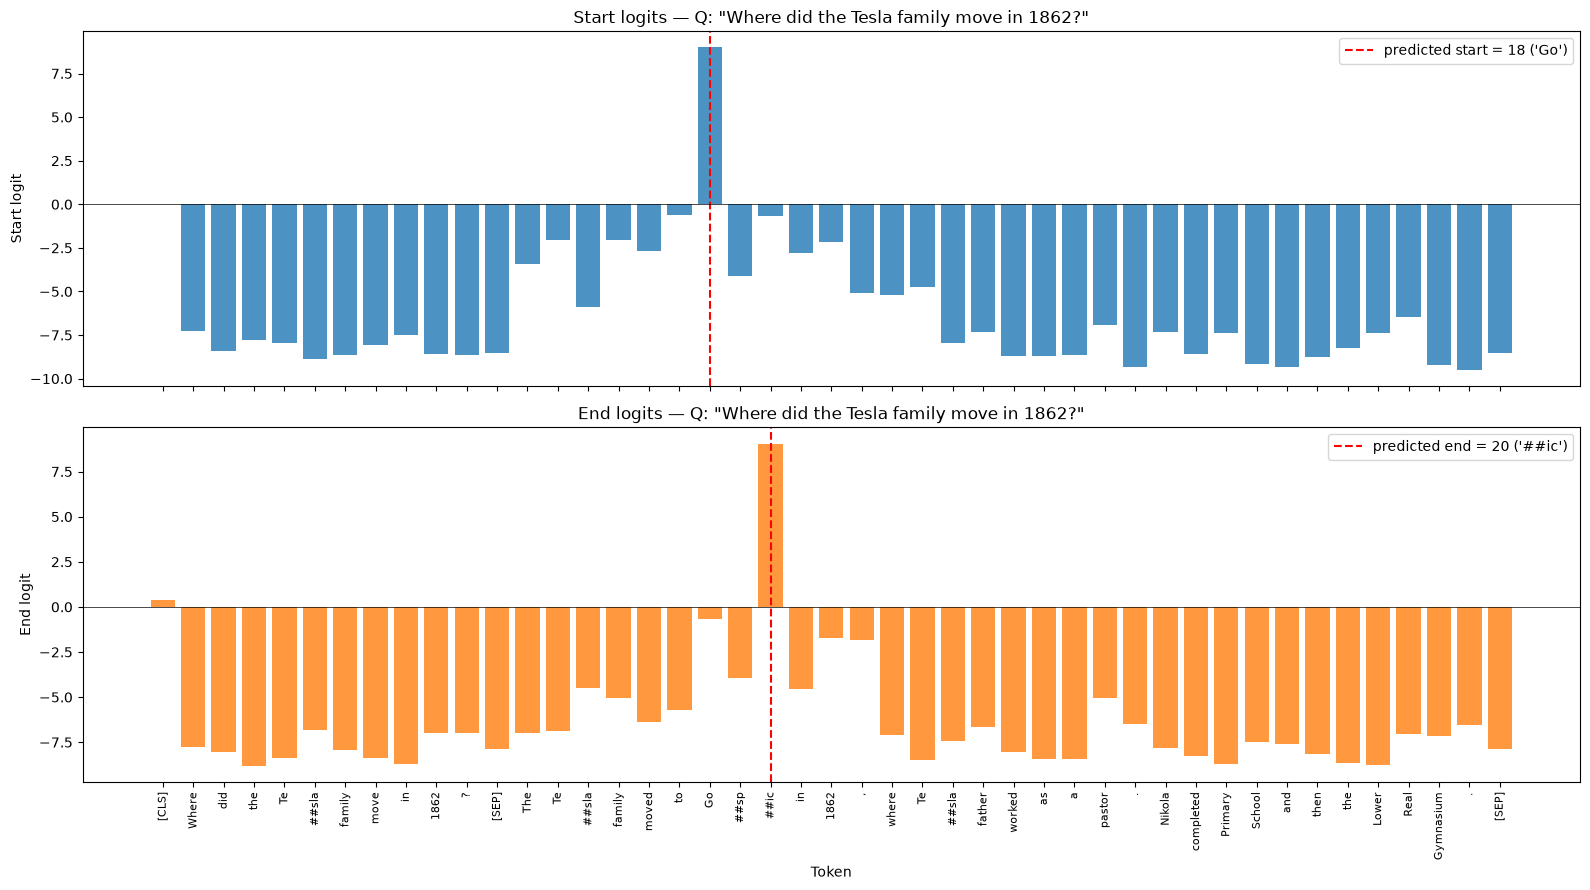

In [12]:
ex = squad_examples[0]
enc = tokenizer(ex['question'], ex['context'], return_tensors='pt').to(qa_model.device)
with torch.no_grad():
    out = qa_model(**enc)
start_logits = out.start_logits[0].cpu().numpy()
end_logits   = out.end_logits[0].cpu().numpy()
tokens = tokenizer.convert_ids_to_tokens(enc['input_ids'][0])

# Predicted positions, restricted to valid context spans (same rule as extract_answer)
seq_ids = enc.sequence_ids(0)
ctx = [i for i, s in enumerate(seq_ids) if s == 1]
best_s, best_e, best = None, None, -np.inf
for s in ctx:
    for e in ctx:
        if s <= e < s + 50 and start_logits[s] + end_logits[e] > best:
            best_s, best_e, best = s, e, start_logits[s] + end_logits[e]
print('Predicted span tokens:', tokens[best_s:best_e + 1])

x = np.arange(len(tokens))
fig, axes = plt.subplots(2, 1, figsize=(16, 9), sharex=True)
for ax, logits, pos, name, color in [
    (axes[0], start_logits, best_s, 'Start', 'tab:blue'),
    (axes[1], end_logits,   best_e, 'End',   'tab:orange'),
]:
    ax.bar(x, logits, color=color, alpha=0.8)
    ax.axvline(pos, color='red', linestyle='--', linewidth=1.5,
               label=f'predicted {name.lower()} = {pos} ({tokens[pos]!r})')
    ax.axhline(0, color='black', linewidth=0.5)
    ax.set_ylabel(f'{name} logit')
    ax.set_title(f'{name} logits — Q: "{ex["question"]}"')
    ax.legend(loc='upper right')
axes[1].set_xticks(x)
axes[1].set_xticklabels(tokens, rotation=90, fontsize=8)
axes[1].set_xlabel('Token')
plt.tight_layout()
plt.show()

### 4.5 Unanswerable Questions (SQuAD v2.0)
The model `deepset/bert-base-cased-squad2` was trained on SQuAD v2.0 which includes unanswerable questions. Run the model on the context and question below. Look at the score — what does a low/high score mean?


In [13]:
context_v2  = 'Tesla attended school in Smiljan where he studied German and arithmetic.'
question_v2 = 'What year was Tesla born?'

answer_v2, score_v2 = extract_answer(question_v2, context_v2, tokenizer, qa_model)
print(f'Q: {question_v2}')
print(f'Best non-null span: {answer_v2!r}   (score = {score_v2:.3f})')

# SQuAD v2 models put "no answer" mass on the [CLS] token (index 0)
enc = tokenizer(question_v2, context_v2, return_tensors='pt').to(qa_model.device)
with torch.no_grad():
    out = qa_model(**enc)
null_score_v2 = float(out.start_logits[0, 0] + out.end_logits[0, 0])
print(f'Null ([CLS]) score : {null_score_v2:.3f}')
print('=> Model abstains (unanswerable)' if null_score_v2 > score_v2 else '=> Model answers')

print('\nComparison with answerable examples:')
print(f"{'Example':<10}{'best span score':>16}{'null score':>12}")
for i, ex in enumerate(squad_examples, 1):
    enc = tokenizer(ex['question'], ex['context'], return_tensors='pt').to(qa_model.device)
    with torch.no_grad():
        out = qa_model(**enc)
    null = float(out.start_logits[0, 0] + out.end_logits[0, 0])
    print(f'{i:<10}{ex["score"]:>16.3f}{null:>12.3f}')
print(f"{'v2 (unans)':<10}{score_v2:>16.3f}{null_score_v2:>12.3f}")

# The HF pipeline does the same comparison internally when handle_impossible_answer=True
qa_pipe = pipeline('question-answering', model=qa_model, tokenizer=tokenizer, device=qa_model.device)
print('\npipeline(handle_impossible_answer=True):',
      qa_pipe(question=question_v2, context=context_v2, handle_impossible_answer=True))

Q: What year was Tesla born?
Best non-null span: 'Tesla attended school in Smiljan'   (score = -8.624)
Null ([CLS]) score : 1.177
=> Model abstains (unanswerable)

Comparison with answerable examples:
Example    best span score  null score
1                   18.045       0.350
2                   13.266      -1.907
3                   17.961       1.266
v2 (unans)          -8.624       1.177

pipeline(handle_impossible_answer=True): {'score': 0.9475793838500977, 'start': 0, 'end': 0, 'answer': ''}


**Your answer:**

**SQuAD v1.1** (Rajpurkar et al., 2016) has ~100k questions, and **every question is answerable** by a span of the passage. A v1.1 model therefore *always* outputs a span, even when the passage says nothing relevant. **SQuAD v2.0** (Rajpurkar et al., 2018) adds ~50k **unanswerable** questions. Crowdworkers wrote them adversarially to look similar to answerable ones: the passage mentions the same entities and contains a plausible-looking distractor span. A system must now also learn **when to abstain**.

**How models handle it:** the **[CLS] token (position 0)** stands for "no answer". During training, unanswerable questions get start = end = 0. At inference we compare the **null score** $s_{null} = S\cdot h_{[CLS]} + E\cdot h_{[CLS]}$ with the best non-null span score $\max_{i\le j} S\cdot h_i + E\cdot h_j$. The model predicts "no answer" if $s_{null} > s_{best} + \tau$, with the threshold $\tau$ tuned on the dev set to maximise F1.

**What we observe:** `extract_answer` is forced to return a span, so for *"What year was Tesla born?"* it returns the meaningless `'Tesla attended school in Smiljan'`. Its score of **−8.62** is far below the answerable examples (**13.3 – 18.0**). The null score (**1.18**) beats the best span. The HF pipeline with `handle_impossible_answer=True` therefore returns the empty answer with probability 0.95.

A **high** span score (well above the null score) means the model is confident that span answers the question. A **low/negative** span score below the null score means no span in the context fits: the question is unanswerable from this passage, and the "answer" should be ignored.

---
## Part 5: QA Evaluation — EM and F1 (15 points)

### 5.1 Implement Normalise, EM and Token F1


In [14]:
import re, string
from collections import Counter

def normalize_answer(text):
    """
    Lowercase, remove articles (a, an, the), remove punctuation, fix whitespace.
    """
    text = text.lower()
    text = ''.join(ch for ch in text if ch not in set(string.punctuation))
    text = re.sub(r'\b(a|an|the)\b', ' ', text)
    return ' '.join(text.split())

def exact_match(prediction, gold_answers):
    """
    Return 1 if prediction exactly matches any gold answer after normalisation, else 0.
    gold_answers is a list of strings.
    """
    pred = normalize_answer(prediction)
    return int(any(pred == normalize_answer(g) for g in gold_answers))

def token_f1(prediction, gold_answers):
    """
    Return the maximum token-level F1 over all gold answers.
    Compute precision and recall on the BAG OF WORDS of the normalised strings.
    """
    pred_toks = normalize_answer(prediction).split()
    best = 0.0
    for g in gold_answers:
        gold_toks = normalize_answer(g).split()
        if not pred_toks or not gold_toks:
            # SQuAD v2 convention: both empty (no-answer) = 1, otherwise 0
            f1 = float(pred_toks == gold_toks)
        else:
            common = Counter(pred_toks) & Counter(gold_toks)
            n_same = sum(common.values())
            if n_same == 0:
                f1 = 0.0
            else:
                p = n_same / len(pred_toks)
                r = n_same / len(gold_toks)
                f1 = 2 * p * r / (p + r)
        best = max(best, f1)
    return best

# Quick tests
print(normalize_answer('  The  German, Arithmetic, and Religion! '))
print(exact_match('the Gospic', ['Gospic']), exact_match('Gospic, Croatia', ['Gospic']))
print(round(token_f1('Gospic, Croatia', ['Gospic']), 3), token_f1('Paris', ['Gospic', 'Paris']))

german arithmetic and religion
1 0
0.667 1.0


### 5.2 Evaluate on the SQuAD Examples
For each example in `squad_examples`, compute EM and F1 between your predicted answer and the gold answer. Print a table of results and average EM and F1.


In [15]:
rows = []
for i, ex in enumerate(squad_examples, 1):
    pred, score = extract_answer(ex['question'], ex['context'], tokenizer, qa_model)
    em = exact_match(pred, [ex['gold']])
    f1 = token_f1(pred, [ex['gold']])
    rows.append((i, ex['gold'], pred, em, f1))

print(f"{'#':<3}{'Gold':<35}{'Prediction':<35}{'EM':>4}{'F1':>8}")
print('-' * 85)
for i, gold, pred, em, f1 in rows:
    print(f'{i:<3}{gold:<35}{pred:<35}{em:>4}{f1:>8.3f}')
print('-' * 85)
avg_em = np.mean([r[3] for r in rows])
avg_f1 = np.mean([r[4] for r in rows])
print(f'Average EM = {avg_em:.3f}   Average F1 = {avg_f1:.3f}')

# Illustration of EM vs F1 on partially-correct predictions
print('\nEM vs F1 on partial answers:')
for pred, gold in [('German and arithmetic', 'German, arithmetic, and religion'),
                   ('about 66.54 percent', '66.54 percent'),
                   ('Gospic in 1862', 'Gospic')]:
    print(f'  pred={pred!r:<28} gold={gold!r:<36} EM={exact_match(pred, [gold])}  F1={token_f1(pred, [gold]):.3f}')

#  Gold                               Prediction                           EM      F1
-------------------------------------------------------------------------------------
1  Gospic                             Gospic                                1   1.000
2  German, arithmetic, and religion   German, arithmetic, and religion      1   1.000
3  66.54 percent                      66.54                                 0   0.667
-------------------------------------------------------------------------------------
Average EM = 0.667   Average F1 = 0.889

EM vs F1 on partial answers:
  pred='German and arithmetic'      gold='German, arithmetic, and religion'   EM=0  F1=0.857
  pred='about 66.54 percent'        gold='66.54 percent'                      EM=0  F1=0.800
  pred='Gospic in 1862'             gold='Gospic'                             EM=0  F1=0.500


### 5.3 Analysis
For any example where EM=0 but F1>0, explain in a markdown cell **why** EM is stricter than F1 and whether the model's answer is actually reasonable.


**Your analysis:**

**Example 3** is the only case with EM = 0 but F1 > 0. Prediction `66.54` vs gold `66.54 percent` gives EM = 0 and F1 = 0.667. After normalisation, the prediction has 1 token and gold has 2 tokens, with 1 token shared. So precision = 1/1, recall = 1/2, and F1 = 2·1·0.5/1.5 = 0.667.

**Why EM is stricter:** EM gives credit only if the normalised strings are *identical*. Any difference in span boundary (an extra or missing unit, adjective, preposition or date) scores 0, exactly like a completely wrong answer. Token F1 treats prediction and gold as bags of words and gives **partial credit for overlap**. It separates "almost right, boundary slightly off" (e.g. `about 66.54 percent` → F1 0.80) from "wrong". Most EM errors on SQuAD are boundary disagreements of this kind. The official evaluation reduces this by taking the max over **several human gold answers** (often 3 annotators), which may include shorter variants.

**Is the model's answer reasonable?** Yes. The question already says *"What percentage …"*, so the unit "percent" is implied, and `66.54` carries all the information asked for. A human grader would mark it correct. EM undervalues this answer, while F1 = 0.667 still under-credits it but reflects it better. This is why SQuAD reports both metrics.

---
## Part 6: Open-Domain QA Pipeline (10 points)

In reading comprehension, the passage is given. In open-domain QA, we must first **retrieve** relevant passages.

### 6.1 Implement a Simple BM25-style Retriever
Given a small corpus of documents and a query, implement `bm25_retrieve(query, corpus, k=3)` that returns the top-k documents using **TF-IDF** scoring (using `sklearn.feature_extraction.text.TfidfVectorizer`).


In [16]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

CORPUS = [
    'Barack Obama was born in Hawaii and served as the 44th US President from 2009 to 2017.',
    'Nikola Tesla was a Serbian-American inventor known for his work on alternating current electricity.',
    'Marie Curie discovered polonium and radium and was the first woman to win the Nobel Prize.',
    'The Eiffel Tower is located in Paris and was constructed between 1887 and 1889.',
    'Python is a high-level programming language created by Guido van Rossum in 1991.',
    'The Amazon rainforest produces 20 percent of the worlds oxygen and spans 9 countries.',
    'Albert Einstein developed the theory of relativity and won the 1921 Nobel Prize in Physics.',
    'The Great Wall of China was built over many centuries to protect Chinese states from invasions.',
]

def bm25_retrieve(query, corpus, k=3):
    """
    Retrieve top-k documents most relevant to the query using TF-IDF.
    Arguments:
        query:  str
        corpus: list of str
        k:      int — number of documents to return
    Returns:
        list of (score, document_string), sorted by score descending
    """
    vectorizer = TfidfVectorizer(stop_words='english', sublinear_tf=True)
    doc_vecs = vectorizer.fit_transform(corpus)
    query_vec = vectorizer.transform([query])
    sims = cosine_similarity(query_vec, doc_vecs)[0]
    top = np.argsort(-sims, kind='stable')[:k]
    return [(float(sims[i]), corpus[i]) for i in top]

# The last query is a paraphrase with no word overlap (AC = alternating current,
# invented ≠ inventor): TF-IDF scores every document 0 — see the DPR answer in 6.3.
for q in ['Where was Barack Obama born?', 'Who discovered radium?', 'When was the Eiffel Tower built?',
          'Who invented AC power?']:
    print(f'Query: {q}')
    for score, doc in bm25_retrieve(q, CORPUS, k=3):
        print(f'  {score:.3f}  {doc}')
    print()

Query: Where was Barack Obama born?
  0.577  Barack Obama was born in Hawaii and served as the 44th US President from 2009 to 2017.
  0.000  Nikola Tesla was a Serbian-American inventor known for his work on alternating current electricity.
  0.000  Marie Curie discovered polonium and radium and was the first woman to win the Nobel Prize.

Query: Who discovered radium?
  0.488  Marie Curie discovered polonium and radium and was the first woman to win the Nobel Prize.
  0.000  Barack Obama was born in Hawaii and served as the 44th US President from 2009 to 2017.
  0.000  Nikola Tesla was a Serbian-American inventor known for his work on alternating current electricity.

Query: When was the Eiffel Tower built?
  0.436  The Eiffel Tower is located in Paris and was constructed between 1887 and 1889.
  0.192  The Great Wall of China was built over many centuries to protect Chinese states from invasions.
  0.000  Barack Obama was born in Hawaii and served as the 44th US President from 2009 t

### 6.2 Build the Full Retriever-Reader Pipeline
Implement `open_domain_qa(question, corpus, retriever, reader_fn, k=3)` that:
1. Retrieves the top-k passages using `retriever`.
2. Runs `reader_fn` (your `extract_answer`) on each passage.
3. Returns the answer with the highest score.


In [17]:
def open_domain_qa(question, corpus, retriever, reader_fn, k=3):
    """
    Arguments:
        question:   str
        corpus:     list of str
        retriever:  callable(query, corpus, k) → list of (score, doc)
        reader_fn:  callable(question, context) → (answer, score)
        k:          number of passages to retrieve
    Returns:
        best_answer: str
        best_score:  float
    """
    best_answer, best_score = '', float('-inf')
    for ret_score, passage in retriever(question, corpus, k):
        if ret_score <= 0:  # no lexical overlap at all with the question
            continue
        answer, score = reader_fn(question, passage)
        if score > best_score:
            best_answer, best_score = answer, score
    return best_answer, best_score

reader = lambda q, c: extract_answer(q, c, tokenizer, qa_model)

# Test it
test_questions = [
    'Where was Barack Obama born?',
    'Who discovered radium?',
    'When was the Eiffel Tower built?',
]
for q in test_questions:
    answer, score = open_domain_qa(q, CORPUS, bm25_retrieve, reader, k=3)
    top_doc = bm25_retrieve(q, CORPUS, k=1)[0][1]
    print(f'Q: {q}')
    print(f'   top passage: {top_doc}')
    print(f'   answer     : {answer!r}   (reader score = {score:.3f})')
    print()

Q: Where was Barack Obama born?
   top passage: Barack Obama was born in Hawaii and served as the 44th US President from 2009 to 2017.
   answer     : 'Hawaii'   (reader score = 15.278)

Q: Who discovered radium?
   top passage: Marie Curie discovered polonium and radium and was the first woman to win the Nobel Prize.
   answer     : 'Marie Curie'   (reader score = -3.974)



Q: When was the Eiffel Tower built?
   top passage: The Eiffel Tower is located in Paris and was constructed between 1887 and 1889.
   answer     : 'between 1887 and 1889'   (reader score = 9.791)



### 6.3 Short Answer
Explain in 3–4 lines why **dense retrieval (DPR)** can find relevant passages that BM25 might miss. Give a concrete example.


**Your answer:**

TF-IDF/BM25 is a **sparse, lexical** retriever: a passage scores > 0 only if it shares the *same surface words* as the query. It has no notion of synonyms, paraphrases, abbreviations or morphology. **DPR** (Karpukhin et al., 2020) encodes the question and each passage with two BERT encoders into dense vectors. It is trained contrastively on (question, gold passage) pairs with in-batch and hard negatives, so relevance is the dot product of *meanings*, not word overlap.

**Concrete example (run in 6.1):** *"Who invented AC power?"* scores **0.0 against every document**. The Tesla passage says "inventor" (not "invented") and "alternating current" (not "AC"), and "power" does not appear at all. So TF-IDF has nothing to match. A dense retriever maps "AC power" ≈ "alternating current electricity" and "invented" ≈ "inventor" to nearby vectors and would rank the Tesla passage first. (The DPR paper's example is similar: *"Who is the bad guy in Lord of the Rings?"* → a passage that only says "villain Sauron".)

---
## Part 7: Connecting Coreference and Question Answering (5 points)

### 7.1 Coref-Aided QA
Consider the passage below where coreference is **required** to answer the question correctly.


In [18]:
coref_passage = (
    'Maria was the top student in her class. '
    'She won the national science prize in 2023. '
    'The award was presented to her by the Prime Minister.'
)
coref_question = 'Who won the national science prize?'

# Step 1: Run coreference resolution on the passage
coref_pred = coref_model.predict(texts=[coref_passage])[0]
print('Step 1 — coreference clusters:')
for cluster in coref_pred.get_clusters(as_strings=True):
    print('   ', ' → '.join(cluster))

def null_score(question, context):
    """Score of the SQuAD v2 'no answer' option ([CLS] start + [CLS] end)."""
    enc = tokenizer(question, context, return_tensors='pt').to(qa_model.device)
    with torch.no_grad():
        out = qa_model(**enc)
    return float(out.start_logits[0, 0] + out.end_logits[0, 0])

# Step 2: Run QA directly on the passage
ans_orig, score_orig = extract_answer(coref_question, coref_passage, tokenizer, qa_model)
ans_orig10, _ = extract_answer(coref_question, coref_passage, tokenizer, qa_model, max_answer_len=10)
print(f'\nStep 2 — QA on original passage : {ans_orig!r}  (score = {score_orig:.3f}, '
      f'null = {null_score(coref_question, coref_passage):.3f})')
print(f'         with max_answer_len=10  : {ans_orig10!r}')

# Step 3: Show how resolving 'She' → 'Maria' helps answer correctly
resolved_passage = coref_passage.replace('She won', 'Maria won').replace(' her by', ' Maria by')
ans_res, score_res = extract_answer(coref_question, resolved_passage, tokenizer, qa_model)
ans_res10, _ = extract_answer(coref_question, resolved_passage, tokenizer, qa_model, max_answer_len=10)
print(f'Step 3 — QA on resolved passage : {ans_res!r}  (score = {score_res:.3f}, '
      f'null = {null_score(coref_question, resolved_passage):.3f})')
print(f'         with max_answer_len=10  : {ans_res10!r}')
print('         resolved passage:', resolved_passage)

# Generic version: replace pronoun mentions by the cluster's first (representative) mention,
# using spaCy tags to keep possessives grammatical (her class → Maria's class)
def resolve_coref(text, pred):
    doc = nlp(text)
    replacements = []
    for spans in pred.get_clusters(as_strings=False):
        head = text[spans[0][0]:spans[0][1]]
        for s, e in spans[1:]:
            span = doc.char_span(s, e)
            if span is None or len(span) != 1 or span[0].pos_ != 'PRON':
                continue
            replacements.append((s, e, head + "'s" if span[0].tag_ == 'PRP$' else head))
    for s, e, new in sorted(replacements, reverse=True):
        text = text[:s] + new + text[e:]
    return text

auto_resolved = resolve_coref(coref_passage, coref_pred)
ans_auto, score_auto = extract_answer(coref_question, auto_resolved, tokenizer, qa_model, max_answer_len=10)
print(f'\nAutomatic coref substitution     : {auto_resolved}')
print(f'QA on auto-resolved passage      : {ans_auto!r}  (score = {score_auto:.3f}, max_answer_len=10)')

Step 1 — coreference clusters:
    Maria → her → She → her
    the national science prize → The award

Step 2 — QA on original passage : 'She won the national science prize in 2023'  (score = -5.194, null = 10.147)
         with max_answer_len=10  : 'She won the national science prize in 2023'


Step 3 — QA on resolved passage : 'Maria won the national science prize in 2023. The award was presented to Maria'  (score = -0.523, null = 9.610)
         with max_answer_len=10  : 'Maria'
         resolved passage: Maria was the top student in her class. Maria won the national science prize in 2023. The award was presented to Maria by the Prime Minister.

Automatic coref substitution     : Maria was the top student in Maria's class. Maria won the national science prize in 2023. The award was presented to Maria by the Prime Minister.
QA on auto-resolved passage      : 'Maria'  (score = -0.372, max_answer_len=10)


### 7.2 Reflection
In 4–5 sentences, explain:
1. Why coreference resolution can improve QA performance.
2. Give a type of question where coref is **essential** (not just helpful).
3. What challenges remain even after combining coref + QA?


**Your reflection:**

1. **Why coref helps QA:** an extractive reader can only copy a span, and the sentence that states the fact ("**She** won the national science prize") often names the entity only with a pronoun. On the original passage our reader returned `'She won the national science prize in 2023'`, because the name `Maria` is in a different sentence from the fact. Coref resolution (FCoref found {Maria, her, She, her} and also {the national science prize, The award}) lets us rewrite the passage so the name sits next to the fact. After that the reader extracts **`Maria`** (with a short answer limit), and the best-span score rises from −5.19 to −0.52 / −0.37.

2. **Where coref is essential:** *who/whom* questions where the asked-about event is only described with a pronoun or definite description (e.g. *"Who was the award presented to?"* → "to **her**"). Without coref, the only span the reader can extract is a pronoun or a non-answer. Multi-sentence / multi-hop questions and open-domain QA over retrieved chunks have the same problem when the retrieved chunk contains "she"/"the company" but not the name.

3. **Remaining challenges:**
   - **Coref errors propagate:** the wrong `her` → Akhila link in TEXT_1 would produce a wrong answer.
   - **Naive substitution can break grammar:** "her class" → "Maria's" needs POS-aware rewriting.
   - **Calibration:** even after resolution, this SQuAD v2 model's null score (≈ 9.6) stays far above any span score, so it would still abstain on *"Who …?"*.
   - **Hard reasoning cases:** bridging/implicit references, cataphora and long-document distance.
   - **Cost:** the pipeline needs two models and is slower.